# Hierarchical clustering applied to wholesale customers

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scipy.cluster.hierarchy as shc

from sklearn.preprocessing import normalize
from sklearn.cluster import AgglomerativeClustering

Agglomerative hierarchical clustering starts with each observation as its own cluster and merges, at each step, the two closest clusters, until there is only one. The result is a tree, the dendrogram: the height at which two branches join is the distance between the clusters merged. The *linkage* defines the distance between two clusters:

- **complete**: the largest distance between an observation of one and an observation of the other,
- **single**: the smallest of those distances,
- **average**: their average,
- **Ward**: the increase in the within-cluster sum of squares produced by the merge.

The data (Wholesale customers, UCI Machine Learning Repository) are the annual spending of 440 clients of a wholesale distributor in six categories of products. Our aim is to make clusters that segment similar clients together.

In [2]:
data = pd.read_csv('wholesale_customers_data.csv')
data.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


`normalize` divides each row by its norm. After it, what matters is not how much a client spends, but how the spending is distributed among the categories (`Channel` and `Region` are small codes, next to the spending they practically do not count).

In [3]:
data_scaled = normalize(data)
data_scaled = pd.DataFrame(data_scaled, columns=data.columns)
data_scaled.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.000112,0.000168,0.708333,0.539874,0.422741,0.011965,0.149505,0.074809
1,0.000125,0.000188,0.442198,0.614704,0.599540,0.110409,0.206342,0.111286
2,0.000125,0.000187,0.396552,0.549792,0.479632,0.150119,0.219467,0.489619
3,0.000065,0.000194,0.856837,0.077254,0.272650,0.413659,0.032749,0.115494
4,0.000079,0.000119,0.895416,0.214203,0.284997,0.155010,0.070358,0.205294


In [4]:
palette = ['#0072B2', '#E69F00', '#009E73', '#CC79A7', '#56B4E9', '#D55E00', '#B8A800']

def cut_height(Z, n_clusters):
    # A height between the merge that leaves n_clusters clusters and the next one
    return (Z[-n_clusters, 2] + Z[-n_clusters+1, 2])/2

def plot_dendrogram(ax, Z, n_clusters=None, title=''):
    # Dendrogram, with the clusters in colors and the cut drawn if n_clusters is given
    shc.set_link_color_palette(palette)
    threshold = cut_height(Z, n_clusters) if n_clusters else 0
    shc.dendrogram(Z, ax=ax, no_labels=True, color_threshold=threshold, above_threshold_color='#555555')
    if n_clusters:
        ax.axhline(threshold, ls='--', color='#c1121f', lw=1.5)
        ax.annotate(f'cut: {n_clusters} clusters', (1, threshold), xycoords=('axes fraction', 'data'), xytext=(-6, 6),
                    textcoords='offset points', ha='right', color='#c1121f', fontsize=10)
    ax.set_xlabel('Clients')
    ax.set_ylabel('Distance between the merged clusters')
    ax.set_title(title)
    ax.grid(True, axis='y', alpha=0.25)

def ordered_clusters(Z, n_clusters):
    # Cluster of each observation, numbered from left to right in the dendrogram (to match its colors)
    labels = shc.fcluster(Z, n_clusters, criterion='maxclust')
    leaves = shc.leaves_list(Z)
    order = pd.unique(labels[leaves])
    return np.array([np.where(order == label)[0][0] for label in labels])

## The four linkages

The same data give very different trees. Single linkage merges the clients one by one into a single big cluster (chaining); complete and Ward linkage give compact clusters of similar size.

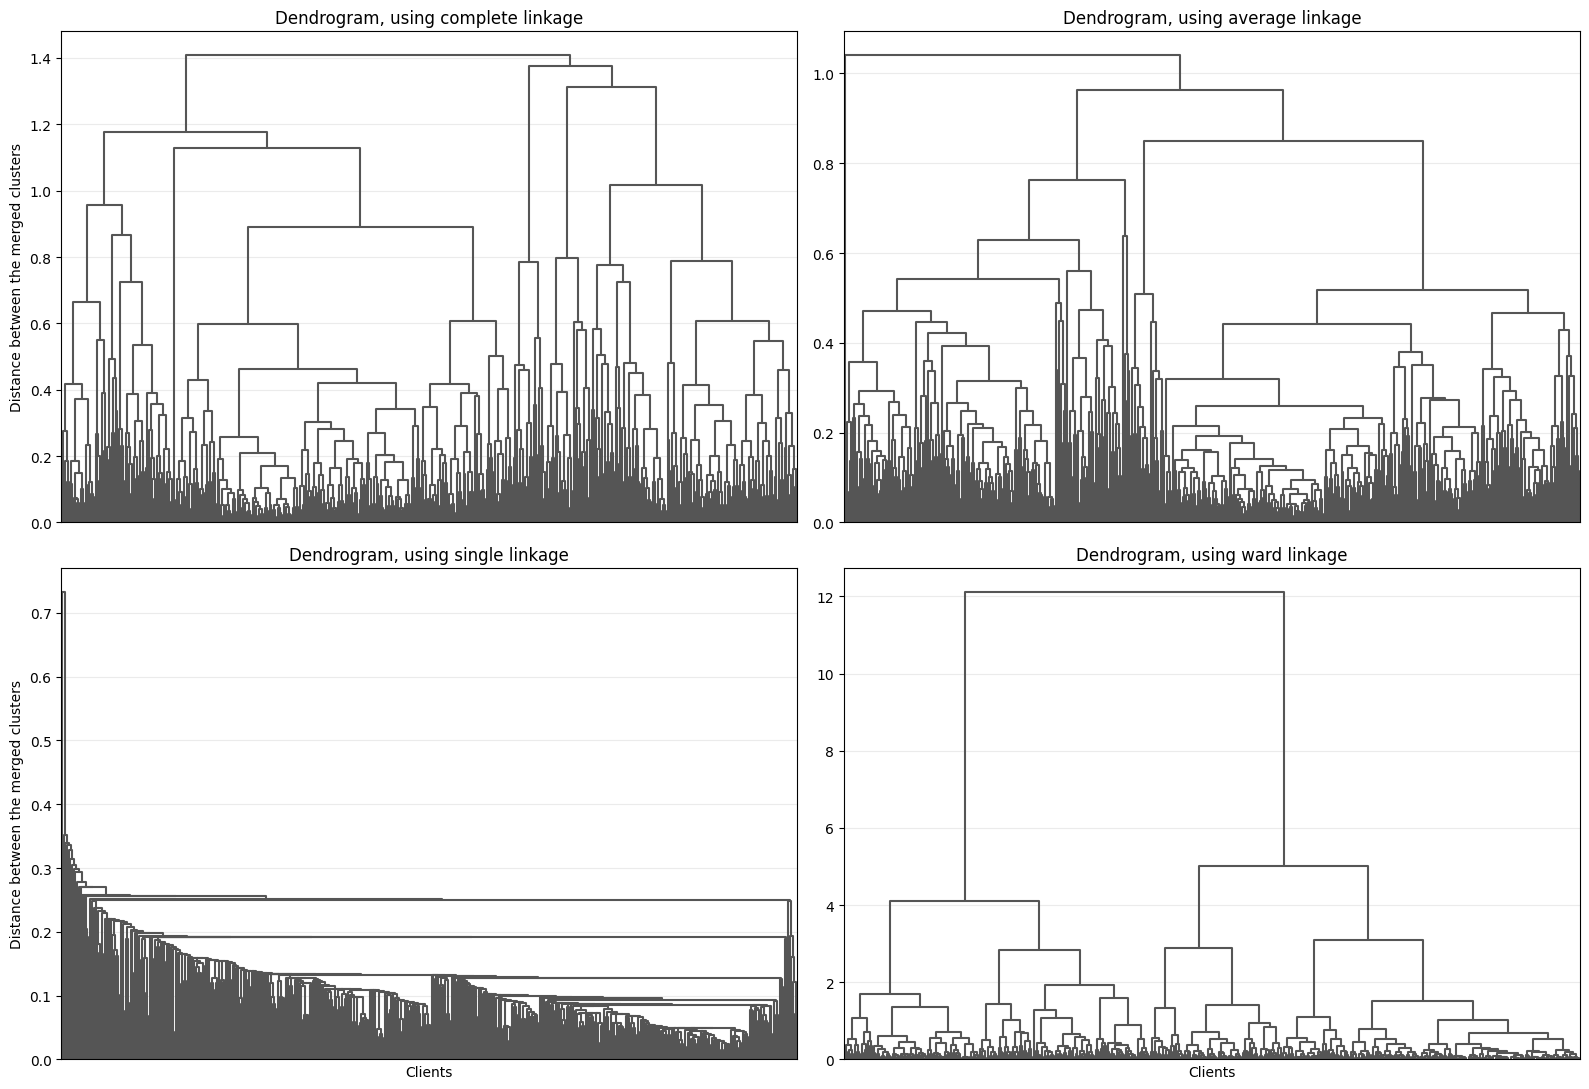

In [5]:
linkages = {method: shc.linkage(data_scaled, method=method) for method in ['complete', 'average', 'single', 'ward']}

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, (method, Z) in zip(axes.ravel(), linkages.items()):
    plot_dendrogram(ax, Z, title=f'Dendrogram, using {method} linkage')
for ax in axes[0]:
    ax.set_xlabel('')
for ax in axes[:, 1]:
    ax.set_ylabel('')
plt.tight_layout()

## Two clusters with Ward linkage

In the dendrogram of Ward the last merge joins two branches at a height much larger than all the previous ones: a sign of two well separated groups.

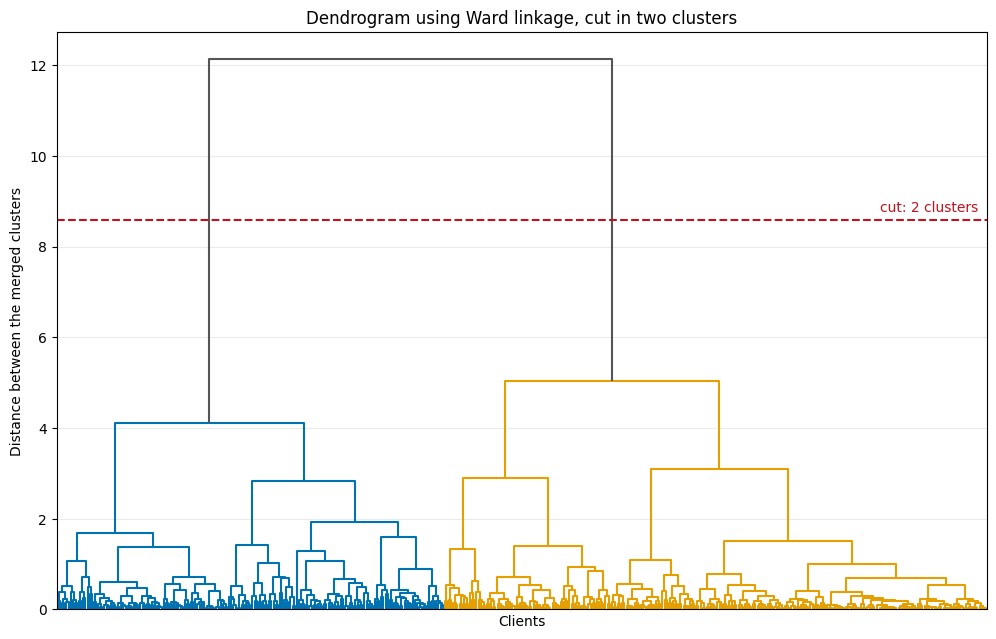

In [6]:
Z = linkages['ward']
n_clusters = 2

fig, ax = plt.subplots(figsize=(12, 7.5))
plot_dendrogram(ax, Z, n_clusters, 'Dendrogram using Ward linkage, cut in two clusters')

In [7]:
cluster_labels = ordered_clusters(Z, n_clusters)
pd.Series(cluster_labels, name='Cluster').value_counts().sort_index()

Cluster
0    183
1    257
Name: count, dtype: int64

`AgglomerativeClustering`, from `sklearn`, gives the same partition (the numbers of the clusters are arbitrary).

In [8]:
cluster = AgglomerativeClustering(n_clusters=2, linkage='ward')
cluster.fit_predict(data_scaled)

pd.crosstab(pd.Series(cluster_labels, name='scipy'), pd.Series(cluster.labels_, name='sklearn'))

sklearn,0,1
scipy,,
0,0,183
1,257,0


## What distinguishes the two clusters?

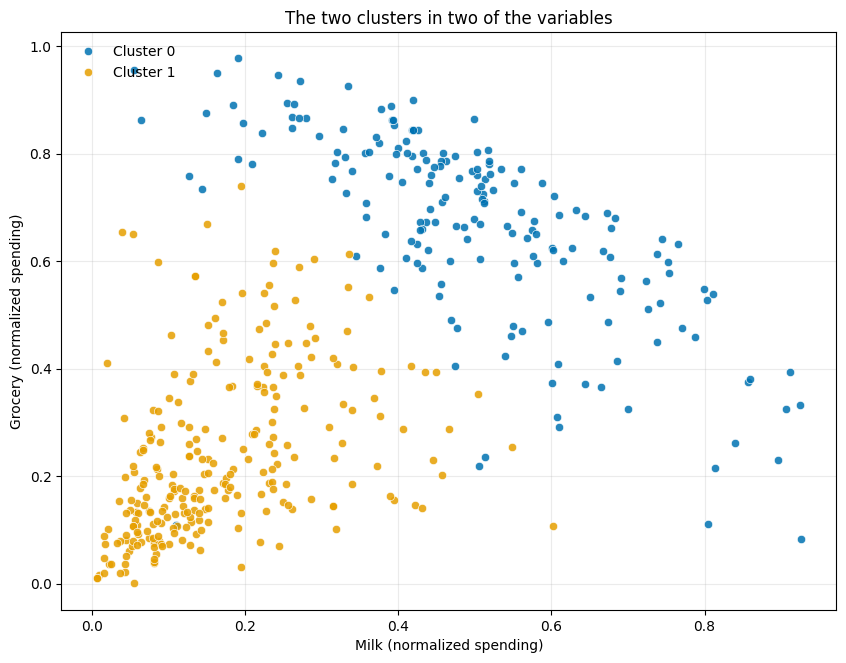

In [9]:
fig, ax = plt.subplots(figsize=(10, 7.5))
for c in range(n_clusters):
    rows = data_scaled[cluster_labels == c]
    ax.plot(rows['Milk'], rows['Grocery'], 'o', color=palette[c], markersize=6, markeredgecolor='white',
            markeredgewidth=0.5, alpha=0.85, label=f'Cluster {c}')
ax.set_xlabel('Milk (normalized spending)')
ax.set_ylabel('Grocery (normalized spending)')
ax.set_title('The two clusters in two of the variables')
ax.legend(loc='upper left', frameon=False)
ax.grid(True, alpha=0.25)

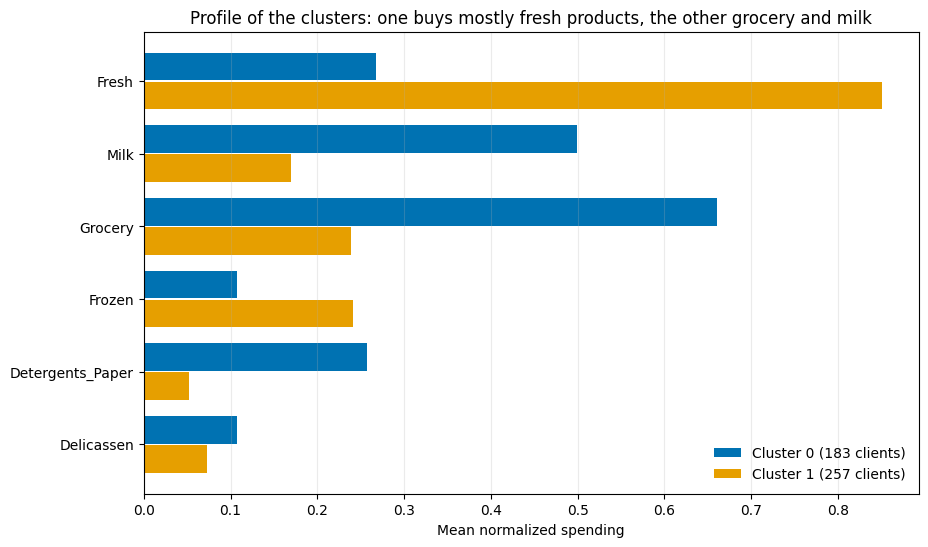

In [10]:
products = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
profiles = data_scaled[products].groupby(cluster_labels).mean()

fig, ax = plt.subplots(figsize=(10, 6))
pos = np.arange(len(products))
for c in range(n_clusters):
    ax.barh(pos + 0.2*(2*c-1), profiles.loc[c], height=0.38, color=palette[c],
            label=f'Cluster {c} ({(cluster_labels == c).sum()} clients)')
ax.set_yticks(pos, products)
ax.invert_yaxis()
ax.set_xlabel('Mean normalized spending')
ax.set_title('Profile of the clusters: one buys mostly fresh products, the other grocery and milk')
ax.legend(loc='lower right', frameon=False)
ax.grid(True, axis='x', alpha=0.25)

The variable `Channel` tells if the client is a hotel, restaurant or cafe (1) or a retailer (2). It practically did not count in the clustering, but the clusters recover a good part of it: the cluster that buys fresh products is made mostly of hotels, restaurants and cafes (87%), and most of the retailers are in the other one.

In [11]:
channel = data['Channel'].map({1: 'Hotel/Restaurant/Cafe', 2: 'Retail'})
pd.crosstab(pd.Series(cluster_labels, name='Cluster'), channel)

Channel,Hotel/Restaurant/Cafe,Retail
Cluster,,
0,74,109
1,224,33
